# 2 · Hierarchical state-space inference

The model uses observed positions with a separate measurement-error term. Latent
OU velocity and position are integrated out by a Kalman likelihood; MCMC estimates
six population parameters and one baseline-amplitude offset per cell.

$$
dv_i=-v_i\,dt/\tau_i+\sqrt{2s_i^2/\tau_i}\,dW_v,
\qquad dx_i=v_i\,dt+j_i\,dW_x,
\qquad y_i=x_i+\epsilon_i.
$$

The hierarchy pools information across cells. Its between-cell SD and localization
SD are **fixed benchmark nuisance values**, not inferred experimental calibrations.

In [1]:
from pathlib import Path
from dataclasses import asdict, replace
from io import BytesIO
import json
import os
import sys

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / 'pyproject.toml').is_file()
             and (p / 'src' / 'motility_inference').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Launch this notebook from the project or its notebooks directory.')
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))
RESULTS = ROOT / 'results' / 'synthetic_v1'
RUN_TRAINING = False  # Large simulation banks and MCMC are never launched by default.
(ROOT / '.cache').mkdir(exist_ok=True)
os.environ.setdefault('XDG_CACHE_HOME', str(ROOT / '.cache'))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.cache' / 'matplotlib'))

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image
from motility_inference.simulator import SimConfig, simulate, load_dataset, proximity
from motility_inference.priors import PARAMETER_NAMES, PRIOR_LOW, PRIOR_HIGH, scenario_theta

plt.rcParams.update({'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})

def show(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format='png', dpi=130, bbox_inches='tight')
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

def read_json(name):
    path = RESULTS / name
    if not path.is_file():
        return None
    try:
        return json.loads(path.read_text())
    except json.JSONDecodeError:
        print(f'{name} is being updated; rerun this cell after the benchmark finishes.')
        return None

print('Project:', ROOT)
print('Cached results:', RESULTS)

Project: /Users/marsian/PhD_LifeSciRes/cell_motility
Cached results: /Users/marsian/PhD_LifeSciRes/cell_motility/results/synthetic_v1


**Conditional-covariate approximation:** the likelihood uses gates calculated from
observed positions and targets. The Gaussian transition is exact given these gates,
but the full model with uncertain positions determining their own gates is nonlinear.
Thus this is not an exact likelihood for every spatial simulator. A good R-hat does
not remove this model approximation. Fine-substep, noise, and mechanics stress tests
explicitly assess departures from its assumptions.

A Laplace covariance preconditions the Metropolis sampler; it is not the reported
posterior. Adaptation stops after warmup and independent chains are diagnosed using
rank R-hat and bulk/tail effective sample sizes.

In [2]:
from motility_inference.state_space import fit, log_likelihood, predict_parameter_paths
case = 'combined'
data_path = RESULTS / 'examples' / f'{case}.npz'
fit_path = RESULTS / 'examples' / f'{case}_ssm.npz'
cached = data_path.is_file() and fit_path.is_file()
if cached:
    data = load_dataset(data_path)
    with np.load(fit_path, allow_pickle=False) as z:
        fitted = {'samples': z['samples'].copy(), 'cell_samples': z['cell_samples'].copy()}
    record = (read_json('state_space.json') or {}).get(case, {})
    diagnostics = record.get('diagnostics', {})
    print('Loaded completed benchmark fit; no MCMC rerun.')
else:
    # A bounded computational example. Its short chains cannot establish recovery.
    data = simulate(scenario_theta(case), SimConfig(n_killers=3, n_frames=41), seed=201)
    fitted = fit(data, draws=80, warmup=80, chains=2, seed=202)
    diagnostics = fitted['diagnostics']
    print('DEMONSTRATION ONLY: cached benchmark absent; short-chain result is not accepted evidence.')
candidate = scenario_theta('null')
print('Illustrative log likelihood at a null candidate with zero cell offsets:',
      log_likelihood(data, candidate))
print('This single value is not a model comparison or a Bayes factor.')
display(pd.Series({k: diagnostics.get(k, 'not available')
                   for k in ('max_rhat', 'min_ess_bulk', 'min_ess_tail', 'converged')}))
sampling_pass = bool(diagnostics.get('converged', False))
if not sampling_pass:
    print('EXPLORATORY ONLY: this representative fit did not pass the sampling gate. Do not treat its intervals as accepted results.')

Loaded completed benchmark fit; no MCMC rerun.
Illustrative log likelihood at a null candidate with zero cell offsets: -5311.416449081721
This single value is not a model comparison or a Bayes factor.


max_rhat           1.003118
min_ess_bulk    1674.796871
min_ess_tail     2326.36621
converged              True
dtype: object

,synthetic_truth,posterior_median,lower90,upper90
parameter,,,,
log_speed,1.163151,1.119403,0.968239,1.270666
log_tau,0.470004,0.550187,0.386675,0.710096
log_jitter,-0.356675,-0.365058,-0.428779,-0.306959
delta_speed,-0.800000,-0.803671,-1.044535,-0.584062
delta_tau,-0.800000,-1.098993,-1.192068,-0.822025
delta_jitter,0.800000,0.737813,0.645226,0.832545


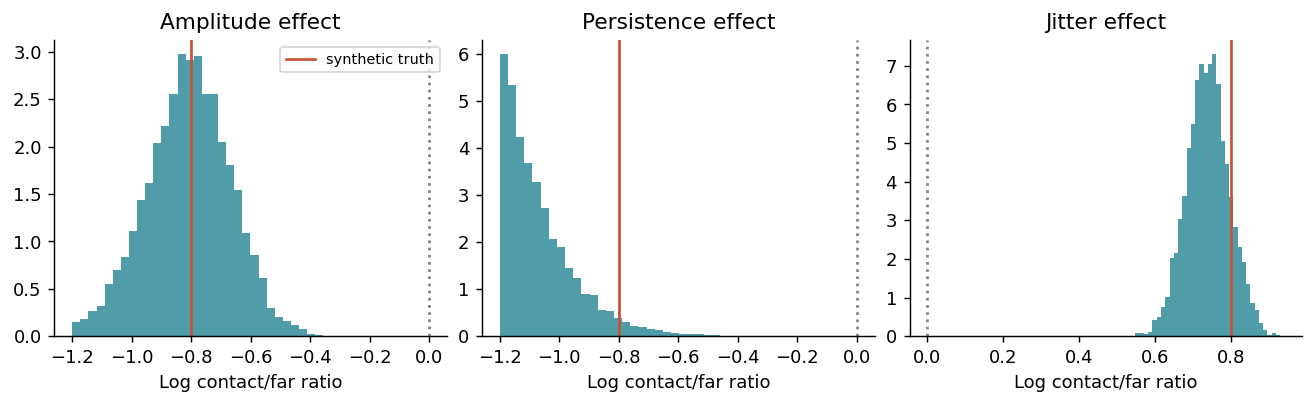

In [3]:
samples = fitted['samples'].reshape(-1, 6)
low, median, high = np.quantile(samples, [.05, .5, .95], axis=0)
table = pd.DataFrame({'parameter': PARAMETER_NAMES, 'synthetic_truth': data['theta'],
                      'posterior_median': median, 'lower90': low, 'upper90': high})
display(table.set_index('parameter'))
fig, axes = plt.subplots(1, 3, figsize=(10, 3), constrained_layout=True)
for ax, j, label in zip(axes, (3, 4, 5), ('Amplitude effect', 'Persistence effect', 'Jitter effect')):
    ax.hist(samples[:, j], bins=35, density=True, color='#167d8d', alpha=.75)
    ax.axvline(data['theta'][j], color='#c65335', label='synthetic truth')
    ax.axvline(0, color='grey', ls=':')
    ax.set(xlabel='Log contact/far ratio', title=label)
axes[0].legend(fontsize=8)
if not sampling_pass:
    fig.suptitle('Exploratory illustration: sampling diagnostic gate failed')
show(fig)

A parameter path here is the estimated **distance-response function evaluated along
the observed trajectory**. It is not a freely inferred independent value at every
frame. The following bands express pointwise parameter uncertainty, not prediction
intervals for noisy observed speed and not simultaneous confidence bands.

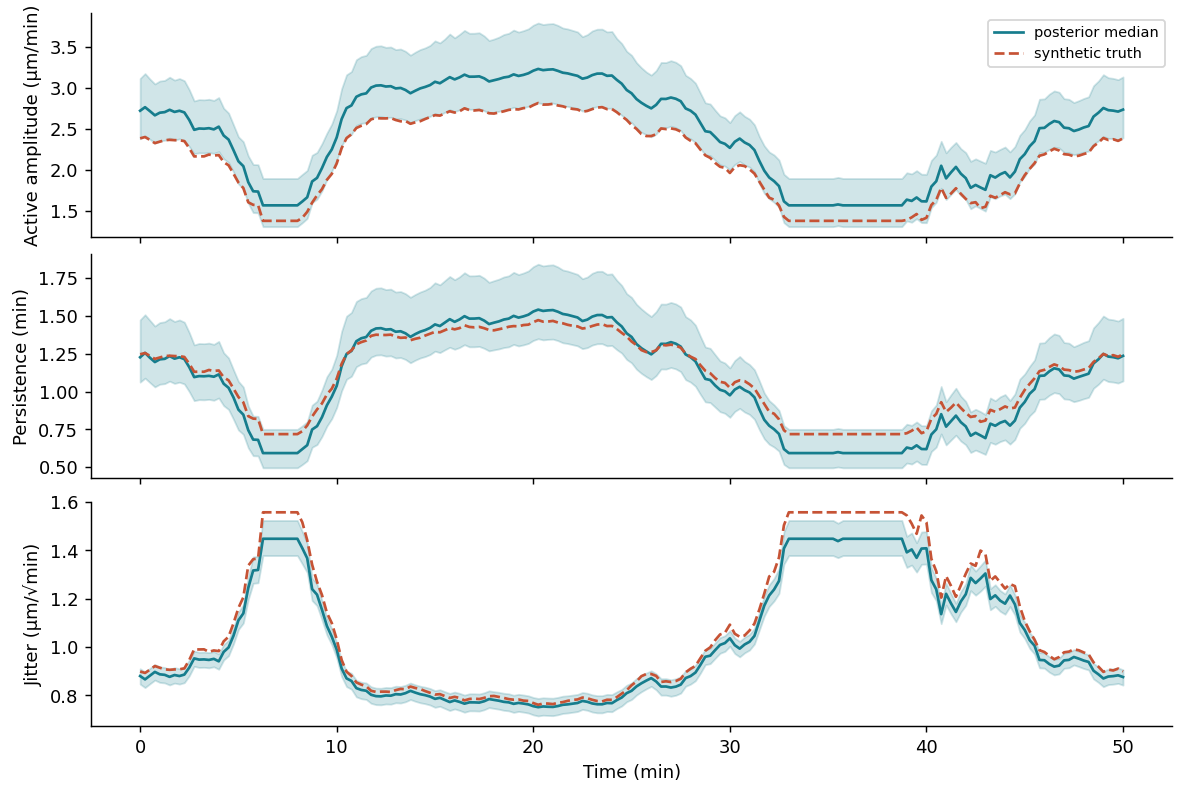

In [4]:
paths = predict_parameter_paths(data, fitted, max_samples=256, seed=203)
cell = int(np.argmax(np.std(paths['gate'], axis=1)))
fig, axes = plt.subplots(3, 1, figsize=(9, 6), sharex=True, constrained_layout=True)
for ax, name, label, b, e in zip(axes, ('speed', 'tau', 'jitter'),
        ('Active amplitude (µm/min)', 'Persistence (min)', 'Jitter (µm/√min)'), (0,1,2), (3,4,5)):
    ax.fill_between(paths['times'], paths[name]['lower'][cell],
                    paths[name]['upper'][cell], color='#167d8d', alpha=.2)
    ax.plot(paths['times'], paths[name]['median'][cell], color='#167d8d', label='posterior median')
    offset = data['cell_offsets'][cell] if b == 0 else 0
    truth = np.exp(data['theta'][b] + offset + data['theta'][e] * data['true_gate'][cell])
    ax.plot(data['times'], truth, color='#c65335', ls='--', label='synthetic truth')
    ax.set_ylabel(label)
axes[0].legend(fontsize=8)
axes[-1].set_xlabel('Time (min)')
if not sampling_pass:
    fig.suptitle('Exploratory parameter paths: sampling diagnostic gate failed')
show(fig)

The global interval may include zero because the data are weak, not because the null
is established. The benchmark separately reports posterior probability of a practical
directional effect and probability of lying within a predefined equivalence region.
For real data, localization accuracy, heterogeneity, contact geometry, and the response
length scale would need calibration or sensitivity analysis.

Background: [Metzner et al. (2015)](https://pmc.ncbi.nlm.nih.gov/articles/PMC4491834/)
established time-varying migration inference. This model is a separate implementation
with explicit target covariates. [ArviZ diagnostics](https://python.arviz.org/en/stable/api/diagnostics.html)
describe the reported sampling checks.